In [7]:
import sys
import os
import re
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# تنظیم و افزودن ریشه پروژه به sys.path
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.preprocessing import extract_review_sentences, clean_sentence_text

print(f"Project root identified: {project_root}")

Project root identified: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026


In [14]:
import sys
!{sys.executable} -m pip install fastparquet pyarrow
# خواندن فایل نقدهای پردازش‌شده با موتور fastparquet
data_path = project_root / "data" / "processed" / "reviews_rc.parquet"
df_all = pd.read_parquet(data_path, engine="fastparquet")

print(f"تعداد کل نقدهای موجود در فایل: {len(df_all):,}")
print("ستون‌های موجود:", df_all.columns.tolist())

# استانداردسازی زمان و استخراج بخش آموزش (Train: 2015 تا 2020)
if not pd.api.types.is_datetime64_any_dtype(df_all["timestamp"]):
    df_all["datetime"] = pd.to_datetime(df_all["timestamp"], unit="ms", errors="coerce")
    if df_all["datetime"].dt.year.isna().all() or df_all["datetime"].dt.year.min() < 2000:
        df_all["datetime"] = pd.to_datetime(df_all["timestamp"], errors="coerce")
else:
    df_all["datetime"] = df_all["timestamp"]

# فیلتر دقیق بر اساس مرزهای زمانی کارت پروژه
train_mask = (df_all["datetime"] >= "2015-01-01") & (df_all["datetime"] <= "2020-12-31")
df_train = df_all[train_mask].copy()

print(f"\nتعداد نقدهای بخش آموزش (Train 2015-2020): {len(df_train):,}")
print(f"بازه زمانی داده آموزش: از {df_train['datetime'].min().date()} تا {df_train['datetime'].max().date()}")

  Using cached fastparquet-2026.9.0-cp314-cp314-win_amd64.whl.metadata (4.9 kB)
  Using cached cramjam-2.14.0-cp314-cp314-win_amd64.whl.metadata (6.7 kB)
Using cached fastparquet-2026.9.0-cp314-cp314-win_amd64.whl (729 kB)
   ---------------------------------------- 0.0/29.8 MB ? eta -:--:--
   --- ------------------------------------ 2.9/29.8 MB 14.6 MB/s eta 0:00:02
   ------------- -------------------------- 9.7/29.8 MB 25.4 MB/s eta 0:00:01
   ---------------------- ----------------- 17.0/29.8 MB 27.9 MB/s eta 0:00:01
   ---------------------------------- ----- 25.7/29.8 MB 30.6 MB/s eta 0:00:01
   ---------------------------------------- 29.8/29.8 MB 28.2 MB/s  0:00:01
Using cached cramjam-2.14.0-cp314-cp314-win_amd64.whl (1.8 MB)

   ---------------------------------------- 0/3 [pyarrow]
   ---------------------------------------- 0/3 [pyarrow]
   ---------------------------------------- 0/3 [pyarrow]
   ---------------------------------------- 0/3 [pyarrow]
   ------------------


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


تعداد کل نقدهای موجود در فایل: 862,444
ستون‌های موجود: ['rating', 'title', 'text', 'images', 'n_images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']

تعداد نقدهای بخش آموزش (Train 2015-2020): 483,429
بازه زمانی داده آموزش: از 2015-01-01 تا 2020-12-30


In [15]:
# تعیین حجم نمونه برای استخراج جملات و خوشه‌بندی فاز ۲
# ۵۰ هزار نقد بیش از ۱۵۰ هزار جمله غنی برای کشف الگو در اختیار ما می‌گذارد
SAMPLE_SIZE = 50000

if SAMPLE_SIZE and len(df_train) > SAMPLE_SIZE:
    df_sample = df_train.sample(n=SAMPLE_SIZE, random_state=42).copy()
    print(f"نمونه‌برداری با حجم ثابت: {len(df_sample):,} نقد")
else:
    df_sample = df_train.copy()

print("در حال استخراج جملات نقدها...")
# اجرای تابع تقطیع سطح جمله
df_sentences = extract_review_sentences(
    df=df_sample,
    text_col="text",
    min_words=3
)

print(f"تعداد کل جملات استخراج‌شده: {len(df_sentences):,}")
display(df_sentences.head(5))

نمونه‌برداری با حجم ثابت: 50,000 نقد
در حال استخراج جملات نقدها...
تعداد کل جملات استخراج‌شده: 139,520


,parent_asin,rating,timestamp,sentence_id,sentence_text,sentence_word_count
0,B00CEP8M86,2.0,1546295654062,rev_0,The truck seemed great until the battery blew ...,14
1,B09X354SZ1,5.0,1577285900158,rev_0,Like the durability and ease of use for my 7 y...,12
2,B08T8TWPZ1,5.0,1570159727624,rev_0,"Super easy to learn, even does tricks.",7
3,B08T8TWPZ1,5.0,1570159727624,rev_1,Good indoor trainer drone,4
4,B07HQFLT48,5.0,1550336872297,rev_0,A good product for younger children who want a...,10


خلاصه توزیع طول جملات (تعداد کلمات):
count    139520.000000
mean         13.893320
std          11.858584
min           3.000000
5%            3.000000
25%           7.000000
50%          11.000000
75%          17.000000
95%          33.000000
99%          57.000000
max         431.000000
Name: sentence_word_count, dtype: float64


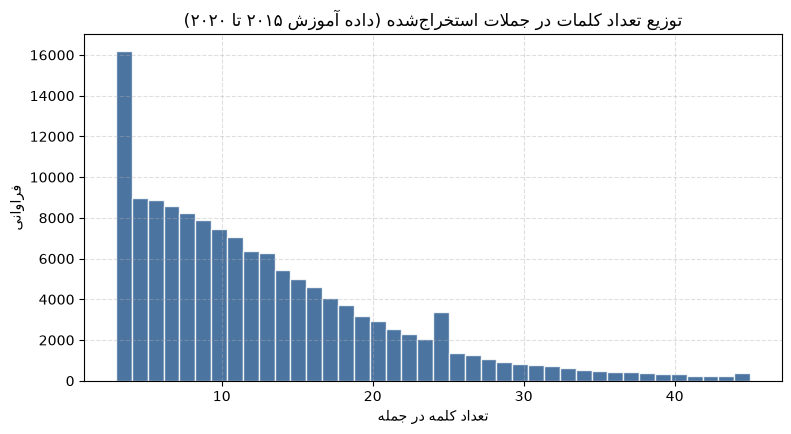

نمودار با موفقیت ذخیره شد در: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026\figures\phase2\sentence_length_distribution.png


In [16]:
# خلاصه آماری طول جملات
stats = df_sentences["sentence_word_count"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
print("خلاصه توزیع طول جملات (تعداد کلمات):")
print(stats)

# رسم نمودار هیستوگرام توزیع طول جملات
plt.figure(figsize=(9, 4.5))
plt.hist(df_sentences["sentence_word_count"], bins=40, range=(3, 45), color="#2b5c8f", edgecolor="white", alpha=0.85)
plt.title("توزیع تعداد کلمات در جملات استخراج‌شده (داده آموزش ۲۰۱۵ تا ۲۰۲۰)", fontsize=12)
plt.xlabel("تعداد کلمه در جمله", fontsize=10)
plt.ylabel("فراوانی", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.4)

# ذخیره تصویر در پوشه figures/phase2
figures_dir = project_root / "figures" / "phase2"
figures_dir.mkdir(parents=True, exist_ok=True)
plot_path = figures_dir / "sentence_length_distribution.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"نمودار با موفقیت ذخیره شد در: {plot_path}")

In [17]:
# ذخیره کل ۱۳۹ هزار جمله روی دیسک جهت استفاده‌های بعدی
interim_dir = project_root / "data" / "interim"
interim_dir.mkdir(parents=True, exist_ok=True)
sentences_save_path = interim_dir / "train_sentences_extracted.parquet"
df_sentences.to_parquet(sentences_save_path, engine="fastparquet", index=False)
print(f"کل جملات ذخیره شدند در: {sentences_save_path}")

# انتخاب زیرنمونه ۲۰ هزار جمله‌ای جهت یادگیری بازنمایی و خوشه‌بندی سریع و تکرارپذیر
EMBED_SAMPLE_SIZE = 20000
if len(df_sentences) > EMBED_SAMPLE_SIZE:
    df_cluster_sample = df_sentences.sample(n=EMBED_SAMPLE_SIZE, random_state=42).reset_index(drop=True)
else:
    df_cluster_sample = df_sentences.reset_index(drop=True)

print(f"تعداد جملات انتخاب‌شده برای ساخت فضا و بازنمایی: {len(df_cluster_sample):,}")

کل جملات ذخیره شدند در: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026\data\interim\train_sentences_extracted.parquet
تعداد جملات انتخاب‌شده برای ساخت فضا و بازنمایی: 20,000


In [20]:
%%time
import sys
!{sys.executable} -m pip install scikit-learn sentence-transformers umap-learn
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

sentences_list = df_cluster_sample["sentence_text"].tolist()

# ۱. بازنمایی کلاسیک: TF-IDF روی n-gramهای کلمات
print("۱. در حال محاسبه ماتریس TF-IDF...")
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english",
    min_df=5
)
X_tfidf = tfidf_vectorizer.fit_transform(sentences_list)
print(f"ابعاد ماتریس تنک TF-IDF: {X_tfidf.shape}")

# ۲. بازنمایی متراکم نوین: Sentence Embeddings
print("\n۲. در حال استخراج بردارهای متراکم معنایی (all-MiniLM-L6-v2)...")
embed_model = SentenceTransformer("all-MiniLM-L6-v2")
X_embeddings = embed_model.encode(
    sentences_list, 
    batch_size=64, 
    show_progress_bar=True,
    normalize_embeddings=True
)
print(f"ابعاد ماتریس متراکم Embeddings: {X_embeddings.shape}")

  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached sentence_transformers-6.2.0-py3-none-any.whl.metadata (20 kB)
  Using cached umap_learn-0.5.12-py3-none-any.whl.metadata (24 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached transformers-5.22.2-py3-none-any.whl.metadata (31 kB)
  Using cached tokenizers-0.23.3-cp310-abi3-win_amd64.whl.metadata (10 kB)
  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
  Using cached torch-2.15.0-cp314-cp314-win_amd64.whl.metadata (36 kB)
  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.8.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached httpx2-2.16.0-py3-none-any.whl.metadata (10 kB)
  Using cached httpcore2-2.16.0-py3-none-any.whl.metadata (27 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached truststore-0.10.5-py3-


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\SARIR\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


۱. در حال محاسبه ماتریس TF-IDF...
ابعاد ماتریس تنک TF-IDF: (20000, 4585)

۲. در حال استخراج بردارهای متراکم معنایی (all-MiniLM-L6-v2)...


c:\Users\SARIR\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\SARIR\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\SARIR\AppData\Local\Programs\Python\Python314\Lib\site-packages\hu

ابعاد ماتریس متراکم Embeddings: (20000, 384)
CPU times: total: 8min 4s
Wall time: 10min 21s


In [22]:
import numpy as np

# ذخیره بردارهای استخراج‌شده در data/interim
embeddings_save_path = interim_dir / "train_embeddings_20k.npy"
np.save(embeddings_save_path, X_embeddings)
print(f"بردارهای معنایی با موفقیت در کش ذخیره شدند: {embeddings_save_path}")

بردارهای معنایی با موفقیت در کش ذخیره شدند: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026\data\interim\train_embeddings_20k.npy


In [21]:
%%time
import umap

print("در حال اجرای کاهش بعد UMAP...")
# نگاشت به فضای دوبعدی جهت مصورسازی و تحلیل چشمی توزیع مفاهیم
reducer_2d = umap.UMAP(
    n_components=2, 
    n_neighbors=15, 
    min_dist=0.1, 
    metric="cosine", 
    random_state=42
)
X_umap_2d = reducer_2d.fit_transform(X_embeddings)

# نگاشت به فضای ۵بعدی جهت حذف نویز قبل از خوشه‌بندی
reducer_dense = umap.UMAP(
    n_components=5, 
    n_neighbors=15, 
    min_dist=0.0, 
    metric="cosine", 
    random_state=42
)
X_umap_clustering = reducer_dense.fit_transform(X_embeddings)

print(f"ابعاد فضای کاهش‌یافته جهت مصورسازی: {X_umap_2d.shape}")
print(f"ابعاد فضای فشرده جهت خوشه‌بندی: {X_umap_clustering.shape}")

در حال اجرای کاهش بعد UMAP...


c:\Users\SARIR\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\SARIR\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


ابعاد فضای کاهش‌یافته جهت مصورسازی: (20000, 2)
ابعاد فضای فشرده جهت خوشه‌بندی: (20000, 5)
CPU times: total: 2min 7s
Wall time: 2min 7s


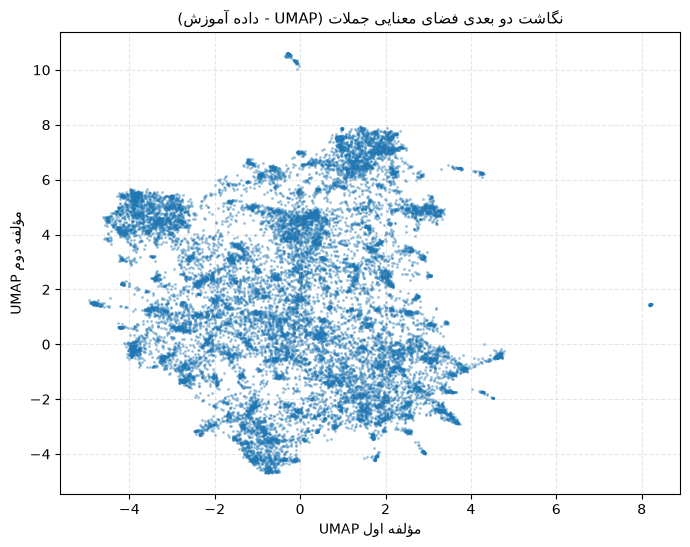

نقشه فضای بازنمایی ذخیره شد در: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026\figures\phase2\umap_sentence_semantic_space.png


In [23]:
plt.figure(figsize=(8, 6))
plt.scatter(X_umap_2d[:, 0], X_umap_2d[:, 1], s=1.5, alpha=0.3, color="#1f77b4")
plt.title("نگاشت دو بعدی فضای معنایی جملات (UMAP - داده آموزش)", fontsize=11)
plt.xlabel("مؤلفه اول UMAP")
plt.ylabel("مؤلفه دوم UMAP")
plt.grid(True, linestyle="--", alpha=0.3)

plot_umap_path = figures_dir / "umap_sentence_semantic_space.png"
plt.savefig(plot_umap_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"نقشه فضای بازنمایی ذخیره شد در: {plot_umap_path}")